![Banner](../images/09_05_banner_rs_hyperspect.png)


# Preprocessing Hyperspectral Cubes

Before any analysis a hyperspectral cube needs cleaning: bands inside atmospheric absorption
windows carry no surface signal, pushbroom detectors leave stripes, clouds and water must be masked,
radiance must become reflectance, and spectra are often smoothed, differentiated, normalised or
continuum removed to bring out absorption features. This notebook works through each step on real
Tanager and OHS data with `geolattice.rsense.hyperspectral`, checks the results against the products'
own uncertainty and cloud layers, and ends by simulating Sentinel-2 bands from a Tanager cube.


## Overview

### Bad bands

Three groups of bands are usually removed: the opaque water vapour windows near 1400 and 1900 nm
(and beyond about 2450 nm), the ends of the range where detector response and solar irradiance are
low (below about 400 nm), and individual bands that are noisy, saturated or mostly fill. Products
often ship a good band list; checking SNR and NaN fractions catches the rest.

### Noise and SNR

Noise in imaging spectrometers is a mix of photon (shot) noise, which grows with signal, and
detector and readout noise, which does not. Two image based estimates are common: the **shift
difference** method assumes neighbouring pixels share the same signal, so their difference is noise
(it overestimates noise in textured scenes); the **residual** method predicts each band from its
spectral neighbours by regression and takes the residual (Roger and Arnold 1996), which is robust to
spatial texture.

### Striping

Each column of a pushbroom image is seen by one detector element. Small differences in gain and
offset between elements show up as along track **stripes**. Moment matching scales every column to
the band's global mean and standard deviation; it assumes each column sees, on average, the same
mix of surfaces, which holds for long swaths.

### Masks

Clouds, cloud shadow, water and saturated pixels distort statistics and endmembers. Simple
reflectance rules (bright and spectrally flat in the visible for cloud, NDWI for water, dark NIR for
shadow) work as a first pass; mission cloud masks, which use the 1380 nm cirrus band and spectral
tests, are better when available.

### Radiance to reflectance

Physics based atmospheric correction (ISOFIT, ATCOR, FLAASH, the Tanager processor) is the norm.
Without it, scene based approximations are still useful:

- **Empirical line**: a linear fit per band between image values and field measured reflectance
  of at least two targets (dark and bright). Accurate near the targets' conditions.
- **Flat field**: divide every pixel by the spectrum of a bright, spectrally flat area.
- **Internal Average Relative (IAR)**: divide by the scene mean spectrum. Removes the solar and
  atmospheric shape but leaves the scene average's own features in every spectrum.

### Spectral transforms

- **Smoothing** (Savitzky Golay, moving average, Gaussian) reduces band to band noise at the cost of
  some spectral resolution.
- **Derivatives** remove baselines and sharpen features: the first derivative peaks at the red edge
  inflection; the second derivative locates absorption minima.
- **Normalisation** (standard normal variate, vector norm, brightness) removes overall brightness
  differences caused by illumination and topography, keeping shape.
- **Continuum removal** divides a spectrum by its convex hull, so absorption features become dips
  below 1 that can be compared across samples (Clark and Roush 1984). **Band depth**, position,
  width and asymmetry summarise one feature.

### Spectral resampling

Convolving a hyperspectral spectrum with the spectral response functions of a multispectral sensor
simulates that sensor. This links field and satellite spectroscopy, creates training data for
Sentinel-2 or Landsat models and lets products from different sensors be compared.


## Preprocessing with GeoLattice

### Learning objectives

1. Flag bad bands with `hs.bad_bands` and compare them with the product's good band list.
2. Estimate per band noise with the shift and residual methods and compare it with Tanager's
   reflectance uncertainty.
3. Measure and remove detector striping with `hs.destripe`.
4. Build cloud, water and shadow masks with `hs.quality_mask` and check them against the product
   cloud mask.
5. Convert radiance to reflectance with the empirical line, flat field and IAR methods and judge
   them against the surface reflectance product.
6. Smooth, differentiate, normalise and continuum remove spectra, and map absorption band depth.
7. Simulate Sentinel-2 bands with `hs.resample_to_sensor`.

### Data

| Dataset | Use |
|---|---|
| Tanager agriculture scene (surface reflectance, radiance, uncertainty) | Bad bands, noise, calibration, transforms, resampling |
| Tanager agriculture basic radiance swath | Striping in sensor geometry |
| Tanager fire scene (Malibu, December 2024) | Cloud and water masks |
| Tanager energy and mining scene (Permian Basin) | Continuum removal and band depth |
| OHS sample scene (Spain) | Striping in a filter based sensor |

### Contents

- Setup
- Bad bands
- Noise and signal to noise ratio
- Detector striping
- Cloud, water and shadow masks
- From radiance to reflectance
- Smoothing, derivatives and normalisation
- Continuum removal and band depth
- Simulating multispectral sensors
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

GeoLattice 0.3.43


## Bad bands

A 200 by 200 pixel window of the agriculture scene (forest, river and fields) is used for most of
the notebook.


In [2]:
WIN = (slice(250, 450), slice(300, 500))  # rows and columns
sr = hs.read_tanager(tanager_file("agriculture"), window=WIN)  # surface reflectance, all bands
wl = hs.wavelengths(sr)  # band centres (nm)
bad = hs.bad_bands(sr)  # default rules: water vapour windows, < 400 nm, NaN or constant bands, product flags
print("bands:", sr.sizes["band"], "| product flags bad:", int((~sr["good"].values).sum()),
      "| bad_bands flags:", int(bad.sum()))
extra = bad & sr["good"].values  # flagged by bad_bands but good in the product
print("extra bands:", np.round(wl[extra][:6], 1), "...", np.round(wl[extra][-6:], 1))

bands: 426 | product flags bad: 58 | bad_bands flags: 76
extra bands: [ 376.4  381.4  386.4  391.4  396.3 1442.6] ... [2474.2 2479.2 2484.1 2489.1 2494.  2499. ]


with min_snr=5: 191 bands flagged


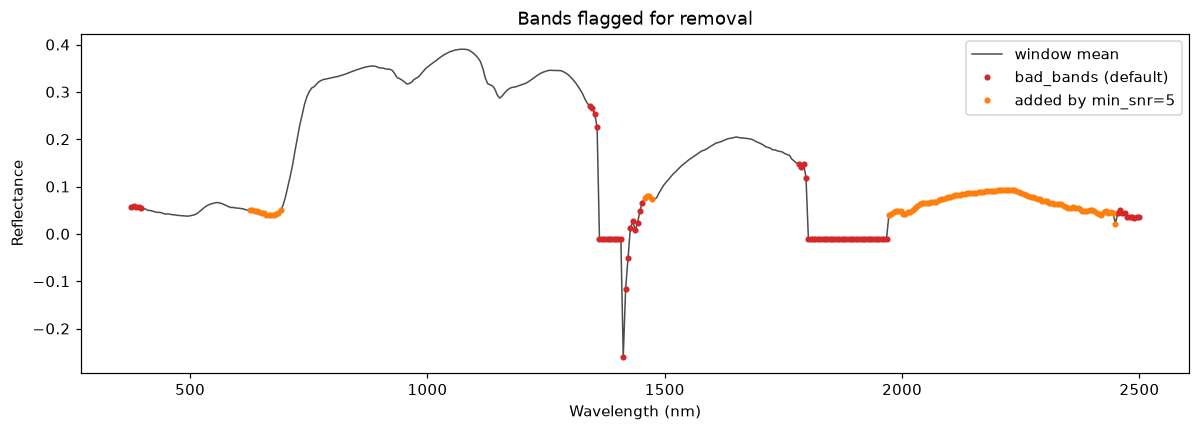

clean cube: (350, 200, 200)


In [3]:
noisy = hs.bad_bands(sr, min_snr=5)  # also drop bands with a simple SNR below 5
print("with min_snr=5:", int(noisy.sum()), "bands flagged")
mean = sr.mean(("y", "x")).values  # window mean spectrum
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(wl, mean, color="0.3", lw=1, label="window mean")
ax.plot(wl[bad], mean[bad], "o", ms=3, color="C3", label="bad_bands (default)")
ax.plot(wl[noisy & ~bad], mean[noisy & ~bad], "o", ms=3, color="C1", label="added by min_snr=5")
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Bands flagged for removal")
ax.legend()
plt.show()
clean = hs.drop_bad_bands(sr)  # remove the default bad bands
print("clean cube:", clean.shape)

The product's own list removes the two opaque water vapour windows. `bad_bands` adds the bands
below 400 nm and beyond 2450 nm, where the spectrum turns noisy (notebook 09_05_00), and a few at
the edge of the 1400 nm window. The SNR threshold is far more aggressive here: it removes the red
chlorophyll absorption (about 620 to 700 nm) and nearly the whole SWIR beyond 1970 nm, simply
because this forest window is dark there and the simple SNR in `band_stats` counts forest texture as
noise. A threshold of 5 is therefore too strict for this scene; check what a rule removes before
applying it.


## Noise and signal to noise ratio

Tanager ships a per pixel, per band reflectance **uncertainty**. Its median over the window is a
useful reference for the two image based noise estimates.


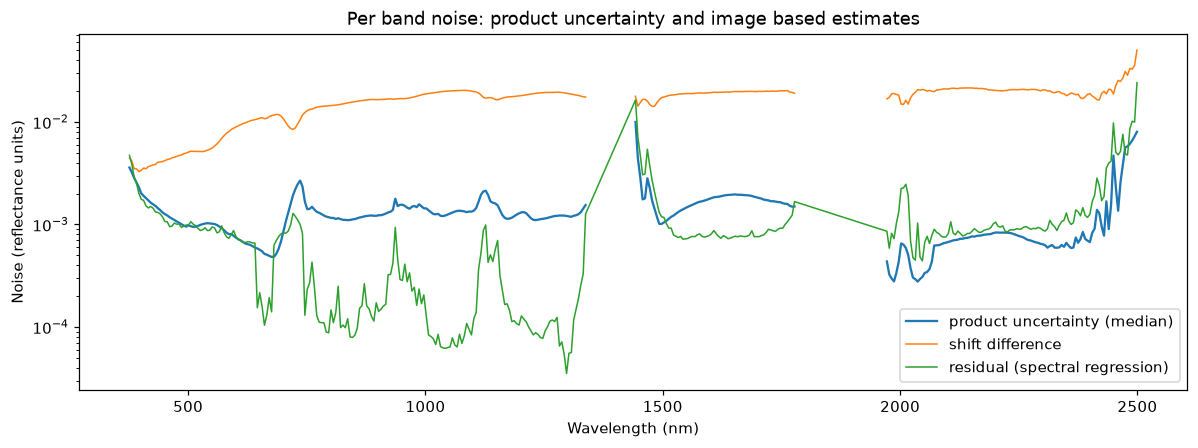

shift / product       13.54
residual / product     0.79
dtype: float64

In [4]:
unc = hs.read_tanager(tanager_file("agriculture"), variable="surface_reflectance_uncertainty", window=WIN)
u = np.nanmedian(unc.values.reshape(unc.sizes["band"], -1), axis=1)  # median uncertainty per band
shift = hs.estimate_noise(sr, method="shift")  # neighbour difference method
resid = hs.estimate_noise(sr.isel(band=np.flatnonzero(sr["good"].values)), method="residual")  # spectral regression
good = sr["good"].values

fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(wl, np.where(good, u, np.nan), label="product uncertainty (median)", lw=1.5)
ax.plot(wl, np.where(good, shift, np.nan), label="shift difference", lw=1)
ax.plot(wl[good], resid, label="residual (spectral regression)", lw=1)
ax.set(xlabel="Wavelength (nm)", ylabel="Noise (reflectance units)", yscale="log",
       title="Per band noise: product uncertainty and image based estimates")
ax.legend()
plt.show()
ratio = pd.Series({"shift / product": np.nanmedian(shift[good] / u[good]),
                   "residual / product": np.nanmedian(resid / u[good])})
ratio.round(2)

All three curves rise at the edges of the water vapour windows and towards 2500 nm, where the
signal is weakest. The shift difference estimate sits more than ten times above the product
uncertainty because neighbouring forest pixels genuinely differ (texture counts as noise). The
residual method, which uses only spectral neighbours, follows the product's error model in the
SWIR and falls below it in the VNIR, where neighbouring 5 nm bands are so strongly correlated that
part of the noise is predictable from them; its median is about 0.8 times the product value. Use the residual
method, or the product uncertainty when it exists, to set SNR thresholds or MNF noise models.


## Detector striping

Striping is easiest to judge in sensor geometry, where every column is one detector element.
Stripes make neighbouring columns differ more than neighbouring rows, so the ratio of the mean
absolute difference across track to the mean absolute difference along track is a simple measure:
about 1 for an image without stripes, above 1 with stripes. (Comparing column means is not a good
check, because moment matching sets them all equal by construction.)


In [5]:
def anisotropy(img):
    """Mean |difference| between neighbouring columns divided by that between neighbouring rows."""
    return float(np.nanmean(np.abs(np.diff(img, axis=1))) / np.nanmean(np.abs(np.diff(img, axis=0))))


swath = hs.read_tanager(DATA / "20250224_145149_32_4001_basic_radiance_hdf5.h5", wavelength_range=(2100, 2300))
swath = swath.rename(line="y", sample="x")  # destripe works on the column (x) axis
ohs = hs.read_ohs(next((DATA / "10m_OH2_Hyperspectral_Sample/Spanish-OHS").iterdir()),
                  bands=[5, 14, 27], window=(slice(1500, 3500), slice(1500, 3500)))  # sensor geometry
ohs = ohs.rename(line="y", sample="x")
rows = []
for name, c in {"Tanager swath (2100 to 2300 nm)": swath, "OHS bands 5, 14, 27": ohs}.items():
    d = hs.destripe(c)  # moment matching per column
    before = np.mean([anisotropy(c.values[b]) for b in range(c.sizes["band"])])  # mean over bands
    after = np.mean([anisotropy(d.values[b]) for b in range(c.sizes["band"])])
    rows.append({"image": name, "anisotropy before": before, "after destripe": after})
pd.DataFrame(rows).round(4)

,image,anisotropy before,after destripe
0,Tanager swath (2100 to 2300 nm),1.0755,1.0578
1,"OHS bands 5, 14, 27",1.0062,1.0087


Both L1 products are already well calibrated. The Tanager swath has a small across track excess
(about 7 percent), which destriping reduces; the OHS bands have none, and destriping changes them
very little. Destriping an image that does not need it only risks removing real differences between
columns. To see what the method can do, the next cell adds synthetic stripes (a random gain of
about 3 percent per column) to the OHS 866 nm band and removes them again.


,anisotropy,RMSE to clean (DN)
clean,0.996,0.000
striped,1.664,4.765
destriped (moment),1.000,8.998
destriped (median),1.069,6.301


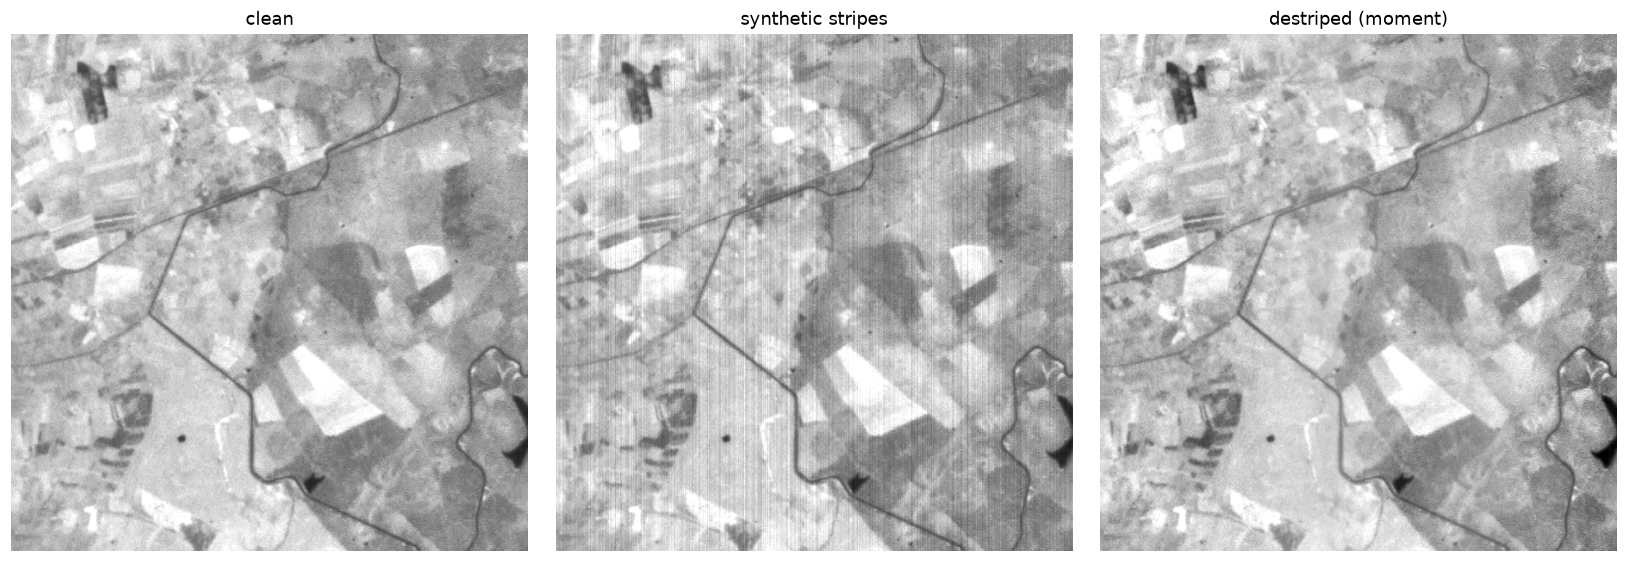

In [6]:
rng = np.random.default_rng(0)
clean = ohs.isel(band=[2])  # OHS band 27 (866 nm)
gain = 1 + rng.normal(0, 0.03, clean.sizes["x"])  # one gain per detector column
striped = clean * gain[None, None, :]  # striped copy
fixed = hs.destripe(striped)  # moment matching
med = hs.destripe(striped, method="median")  # median matching
tab = pd.DataFrame({k: {"anisotropy": anisotropy(v.values[0]),
                        "RMSE to clean (DN)": float(np.sqrt(np.nanmean((v.values - clean.values) ** 2)))}
                    for k, v in {"clean": clean, "striped": striped, "destriped (moment)": fixed,
                                 "destriped (median)": med}.items()}).T
display(tab.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
lo, hi = np.nanpercentile(clean.values, [2, 98])  # common stretch
for ax, (t, v) in zip(axes, [("clean", clean), ("synthetic stripes", striped), ("destriped (moment)", fixed)]):
    ax.imshow(v.values[0, :600, :600], cmap="gray", vmin=lo, vmax=hi)  # 600 x 600 pixel detail
    ax.set_title(t); ax.axis("off")
plt.tight_layout()
plt.show()

The synthetic stripes are obvious and raise the anisotropy from 1.0 to about 1.7. Moment matching
brings it back to the clean value and the stripes disappear from the image, but the RMSE against the
clean band goes **up**, not down. Every column is forced to the same mean and standard deviation, yet
in this 20 km window some columns genuinely cross more reservoir or more bright fields than others;
those real differences are flattened too. Median matching keeps more of them and ends between the
two. Destriping removes visible stripes, but it is a cosmetic and statistical correction that can
bias absolute values. Apply it to long swath segments, preferably with gains from the instrument's
calibration, and do not apply it to data that show no stripes.


## Cloud, water and shadow masks

The fire scene over Malibu has a patch of cloud above the ocean. `hs.quality_mask` needs only the
450, 560, 650 and 860 nm bands (plus 1380 nm for cirrus), so only those are read.


In [7]:
fire = tanager_file("fire")
probe = hs.read_tanager(fire, window=(slice(0, 1), slice(0, 1)))  # wavelengths only
idx = [hs.band_index(probe, w) for w in (450, 560, 650, 860, 1380)]
few = hs.read_tanager(fire, bands=idx)  # five bands of the whole scene
qm = hs.quality_mask(few)  # cloud, water, shadow, saturated, valid (default cloud_blue=0.25)
qm10 = hs.quality_mask(few, cloud_blue=0.10)  # a lower blue threshold for thin cloud
anc = hs.read_tanager_ancillary(fire)  # product masks
prod_cloud = (anc["beta_cloud_mask"] == 1) | (anc["beta_cirrus_mask"] == 1)
inside = np.isfinite(few.isel(band=0)).values  # pixels inside the swath
ours = qm["cloud"].values.astype(bool)
agree = pd.crosstab(pd.Series(prod_cloud.values[inside], name="product cloud"),
                    pd.Series(ours[inside], name="quality_mask cloud"))
print("default:", {k: int(qm[k].values[inside].sum()) for k in ["cloud", "water", "shadow", "saturated", "valid"]})
print("cloud_blue=0.10: cloud", int(qm10["cloud"].values[inside].sum()), "| product cloud + cirrus:", int(prod_cloud.values[inside].sum()))
agree

default: {'cloud': 94, 'water': 234650, 'shadow': 6127, 'saturated': 0, 'valid': 161711}
cloud_blue=0.10: cloud 4248 | product cloud + cirrus: 36


quality_mask cloud,False,True
product cloud,,
False,402456,90
True,32,4


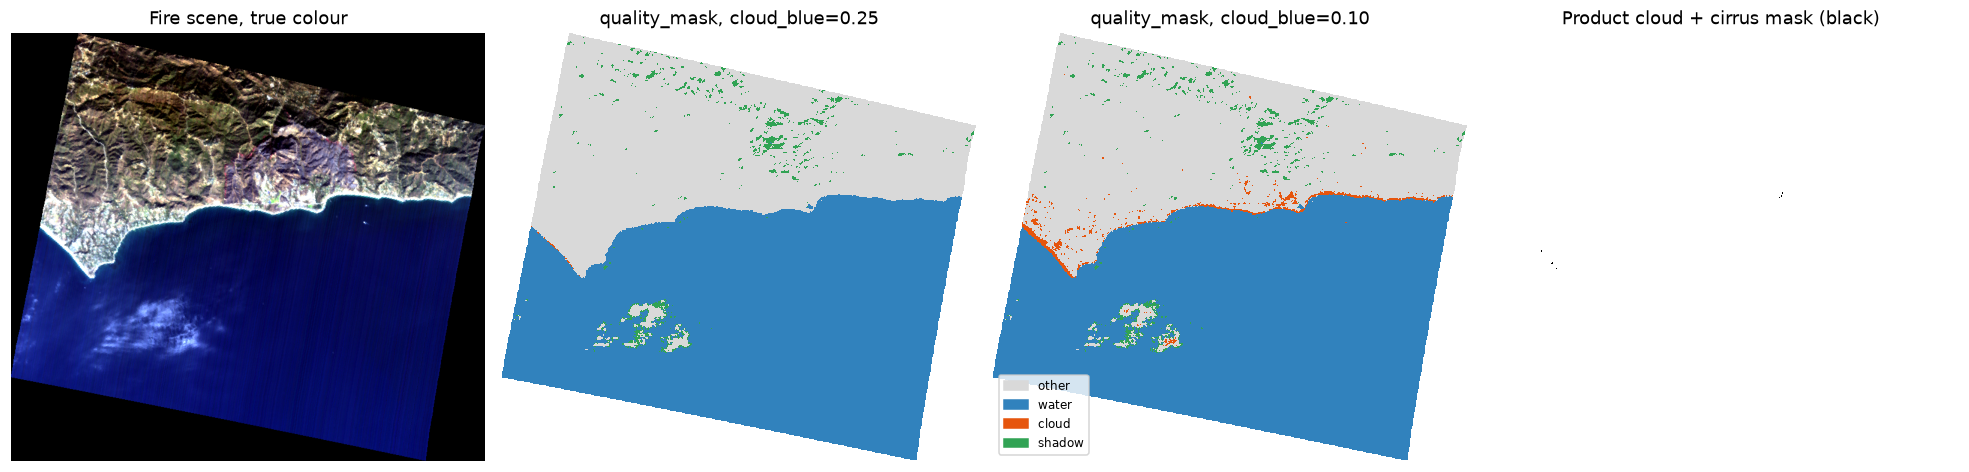

In [8]:
from matplotlib.colors import ListedColormap  # categorical colours
from matplotlib.patches import Patch  # legend entries

cats = ListedColormap(["#d9d9d9", "#3182bd", "#e6550d", "#31a354"])  # other land, water, cloud, shadow
def classes(q):
    """0 other, 1 water, 2 cloud, 3 shadow, NaN outside the swath."""
    return np.where(inside, np.select([q["cloud"] == 1, q["water"] == 1, q["shadow"] == 1], [2, 1, 3], 0), np.nan)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
hs.plot_rgb(few, (650, 560, 450), ax=axes[0], title="Fire scene, true colour")
for ax, q, t in [(axes[1], qm, "quality_mask, cloud_blue=0.25"), (axes[2], qm10, "quality_mask, cloud_blue=0.10")]:
    ax.imshow(classes(q), cmap=cats, vmin=-0.5, vmax=3.5, interpolation="nearest"); ax.set_title(t)
axes[3].imshow(np.where(inside, prod_cloud, np.nan), cmap="Greys", vmin=0, vmax=1, interpolation="nearest")
axes[3].set_title("Product cloud + cirrus mask (black)")
axes[2].legend(handles=[Patch(color=c, label=l) for c, l in zip(cats.colors, ["other", "water", "cloud", "shadow"])],
               loc="lower left", fontsize=8)
for ax in axes[1:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

The thin cloud over the ocean is easy to see in true colour, yet none of the masks flags it. The
product's beta cloud and cirrus masks mark only 36 pixels in the whole scene, and the default rule
(blue reflectance above 0.25) marks 94. Under the cloud the rules see pixels that are no longer
water (the cloud raises the NIR) but are not bright enough for cloud, so they end up as "other",
fringed by "shadow". Lowering the blue threshold to 0.10 does not help: it flags the white surf
line and beaches instead. The water and shadow rules themselves work (ocean against land, steep
shaded slopes in the mountains). Thin cloud over dark water is a known weak point of simple tests; a
scene specific rule, such as treating non water pixels inside the open ocean as suspect, works
better here. Use product masks where they work, add rules where they do not, and always look at the
result.


## From radiance to reflectance

The radiance product of the same window is converted with three scene based methods and compared
with Planet's surface reflectance. For the empirical line, two pixels (the darkest and brightest in
the NIR) play the role of field targets, with the surface reflectance product standing in for field
spectra.


In [9]:
rad = hs.read_tanager(tanager_file("agriculture", "radiance"), window=WIN)  # W m-2 sr-1 um-1
nir = hs.band_at(sr, 860).values
dark = np.unravel_index(np.nanargmin(nir), nir.shape)  # darkest NIR pixel (water)
bright = np.unravel_index(np.nanargmax(nir), nir.shape)  # brightest NIR pixel
targets = {name: ((slice(r - 1, r + 2), slice(c - 1, c + 2)), sr.values[:, r - 1:r + 2, c - 1:c + 2].mean((1, 2)))
           for name, (r, c) in {"dark": dark, "bright": bright}.items()}  # (window, "field" spectrum)
el, coefs = hs.empirical_line(rad, targets)  # per band gain and offset
ff = hs.flat_field(rad, targets["bright"][0])  # divide by the bright target
iar = hs.iar_reflectance(rad)  # divide by the scene mean
print("dark pixel", dark, "| bright pixel", bright)
coefs.iloc[[40, 97, 250, 365]].round(5)

dark pixel (np.int64(116), np.int64(115)) | bright pixel (np.int64(4), np.int64(17))


,wavelength,gain,offset,r2
40,575.82001,0.00227,-0.03067,1.0
97,861.26001,0.00358,-0.00440,1.0
250,1627.66003,0.01451,-0.00026,1.0
365,2201.21997,0.05207,0.00026,1.0


In [10]:
good = sr["good"].values & (wl > 400) & (wl < 2450)  # well-behaved bands
truth = sr.values[good].reshape(good.sum(), -1)  # product reflectance, (bands, pixels)
def mean_angle(e, t):
    """Mean spectral angle (degrees) between estimated and true spectra (columns are pixels)."""
    ok = np.all(np.isfinite(e), 0) & np.all(np.isfinite(t), 0)
    cos = (e[:, ok] * t[:, ok]).sum(0) / (np.linalg.norm(e[:, ok], axis=0) * np.linalg.norm(t[:, ok], axis=0))
    return float(np.degrees(np.arccos(np.clip(cos, -1, 1))).mean())


rows = []
for name, est in [("empirical line", el), ("flat field", ff), ("IAR", iar)]:
    e = est.values[good].reshape(good.sum(), -1)
    ok = np.isfinite(e) & np.isfinite(truth)
    rows.append({"method": name, "output": "reflectance" if name == "empirical line" else "relative",
                 "RMSE (reflectance)": float(np.sqrt(np.mean((e[ok] - truth[ok]) ** 2))) if name == "empirical line" else np.nan,
                 "mean spectral angle to product (deg)": mean_angle(e, truth)})
pd.DataFrame(rows).round(4)

,method,output,RMSE (reflectance),mean spectral angle to product (deg)
0,empirical line,reflectance,0.0087,1.9529
1,flat field,relative,NaN,40.5616
2,IAR,relative,NaN,33.9701


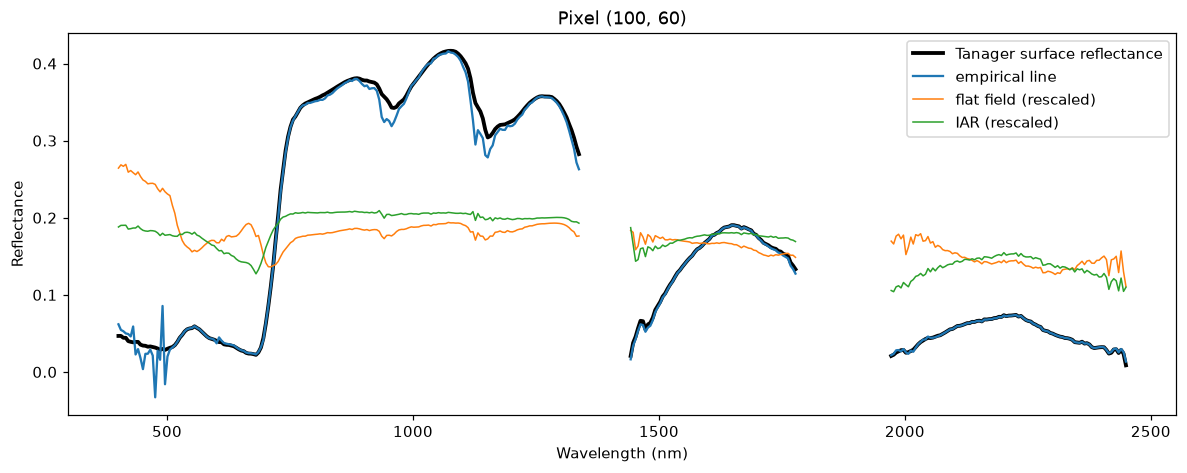

In [11]:
r, c = 100, 60  # a test pixel away from the two targets
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(wl, np.where(good, sr.values[:, r, c], np.nan), lw=2.5, color="k", label="Tanager surface reflectance")
ax.plot(wl, np.where(good, el.values[:, r, c], np.nan), label="empirical line")
for name, est in [("flat field", ff), ("IAR", iar)]:
    v = np.where(good, est.values[:, r, c], np.nan)
    ax.plot(wl, v * np.nanmean(sr.values[:, r, c][good]) / np.nanmean(v[good]), lw=1, label=f"{name} (rescaled)")
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title=f"Pixel ({r}, {c})")
ax.legend()
plt.show()

With two targets the line through them fits exactly (the `r2` of 1 in the coefficient table is
trivial), but it also predicts all other pixels closely: an RMSE below 0.01 and a spectral angle of
about 1 to 2 degrees, because the atmosphere over a 6 km window is nearly uniform and one gain and
offset per band describe it. Flat field and IAR spectra are only relative and inherit the shape of
their reference: divided by a bright vegetated target or by the forest dominated scene mean, the
test pixel loses its red edge and looks nearly flat, which shows up as a spectral angle of tens of
degrees. These methods are fallbacks when no atmospheric correction is
available, for example for laboratory or drone data.


## Smoothing, derivatives and normalisation


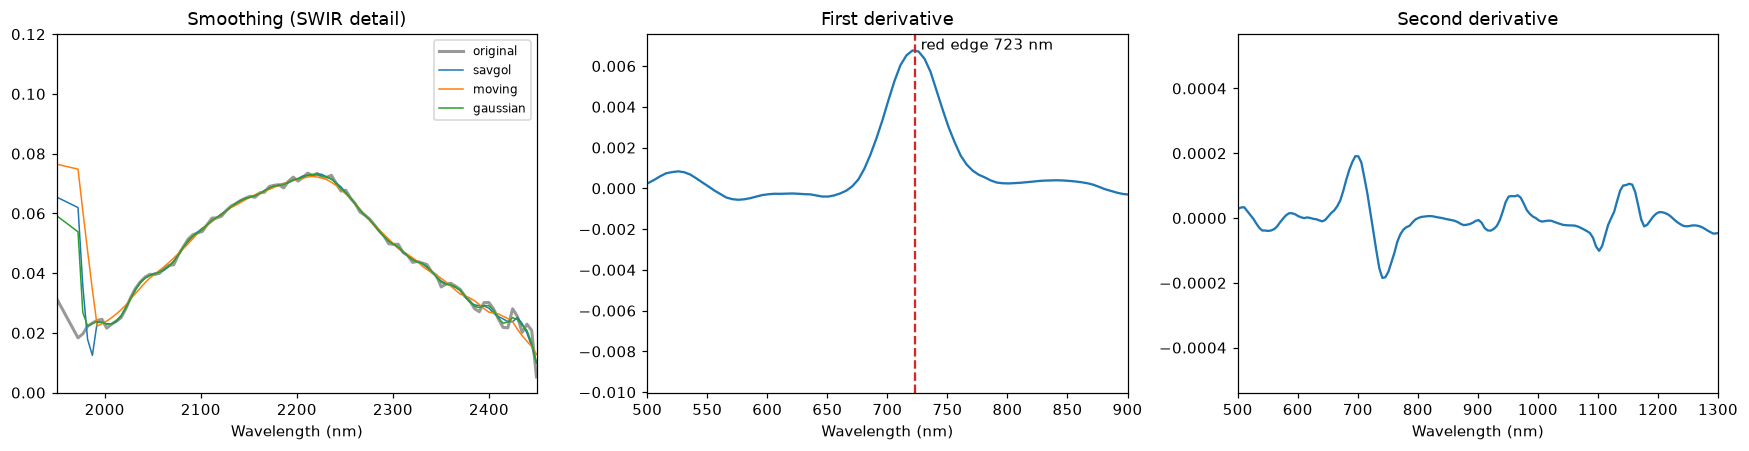

In [12]:
cl = sr.isel(band=np.flatnonzero(good))  # well-behaved bands only
veg_rc = np.unravel_index(np.nanargmax(hs.index(cl, "NDVI").values), nir.shape)  # most vegetated pixel
spec = cl.isel(y=[veg_rc[0]], x=[veg_rc[1]])  # 1 x 1 cube keeps every function usable
sm = {m: hs.smooth(spec, method=m, window=9) for m in ("savgol", "moving", "gaussian")}
d1 = hs.derivative(spec, 1, window=9)  # first derivative (per nm)
d2 = hs.derivative(spec, 2, window=11)  # second derivative

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
w = hs.wavelengths(spec)
axes[0].plot(w, spec.values.ravel(), color="0.6", lw=2, label="original")
for m, s in sm.items():
    axes[0].plot(w, s.values.ravel(), lw=1, label=m)
axes[0].set(xlim=(1950, 2450), ylim=(0, 0.12), title="Smoothing (SWIR detail)", xlabel="Wavelength (nm)")
axes[0].legend(fontsize=8)
axes[1].plot(w, d1.values.ravel()); axes[1].set(xlim=(500, 900), title="First derivative", xlabel="Wavelength (nm)")
rep = float(hs.red_edge_position(spec).values.ravel()[0])  # red edge inflection
axes[1].axvline(rep, color="C3", ls="--"); axes[1].text(rep + 5, axes[1].get_ylim()[1] * 0.9, f"red edge {rep:.0f} nm")
axes[2].plot(w, d2.values.ravel()); axes[2].set(xlim=(500, 1300), title="Second derivative", xlabel="Wavelength (nm)")
plt.tight_layout()
plt.show()

All three smoothers reduce band to band noise in the far SWIR; Savitzky Golay keeps narrow features
best, a moving average flattens them most. The first derivative turns the red edge into a peak whose
position, the red edge inflection, is a chlorophyll and stress indicator (notebook 09_05_04). The
second derivative marks curvature changes such as the shoulders of absorption features.


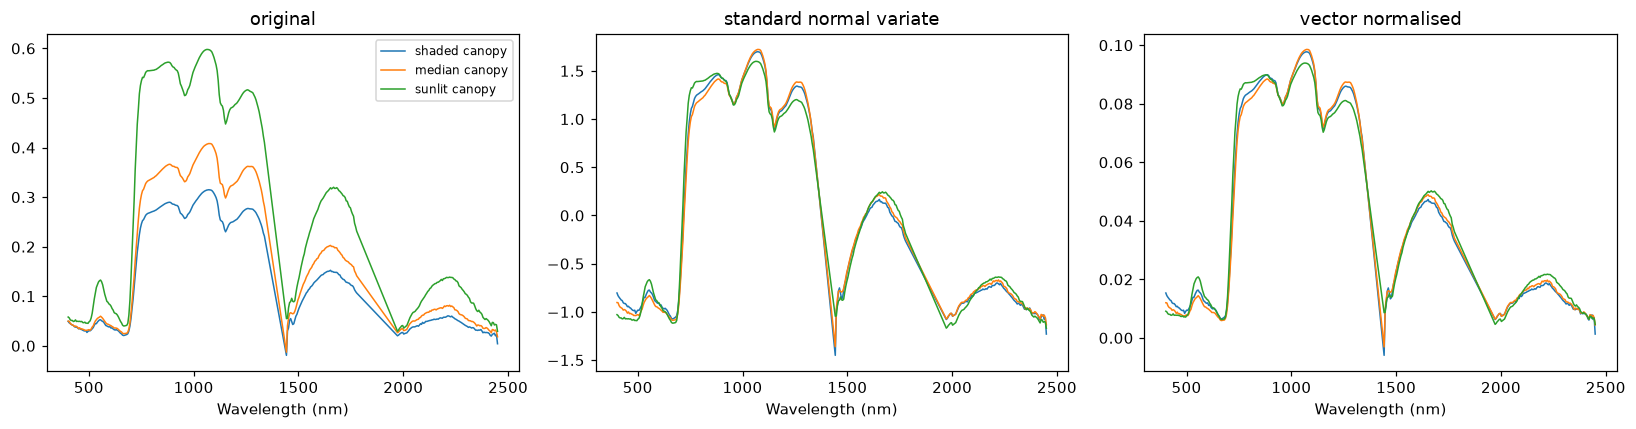

In [13]:
import xarray as xr  # labelled arrays, to pick pixels by index

ndvi = hs.index(cl, "NDVI").values  # narrowband NDVI of the window
forest = np.flatnonzero(ndvi.ravel() > 0.85)  # dense canopy pixels
X = cl.values.reshape(cl.sizes["band"], -1)  # (bands, pixels)
order = np.argsort(X[hs.band_index(cl, 860), forest])  # sort canopy pixels by NIR brightness
pick = forest[order[[5, len(order) // 2, -5]]]  # dark, median and bright canopy
trio = xr.DataArray(X[:, pick][:, None, :], dims=("band", "y", "x"), coords={"wavelength": ("band", hs.wavelengths(cl))})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, c) in zip(axes, [("original", trio), ("standard normal variate", hs.snv(trio)),
                                 ("vector normalised", hs.normalize(trio))]):
    for i, lab in enumerate(["shaded canopy", "median canopy", "sunlit canopy"]):
        ax.plot(hs.wavelengths(c), c.values[:, 0, i], lw=1, label=lab)
    ax.set(title=title, xlabel="Wavelength (nm)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Three dense canopy pixels differ mostly in brightness, because of slope and canopy shadow. After the
standard normal variate (each spectrum centred and scaled) or vector normalisation the curves almost
coincide, leaving only the small differences in shape that carry biochemical information.


## Continuum removal and band depth

The Permian Basin scene is bare caliche and sandy soil with oil and gas pads. Clays absorb near
2200 nm (Al-OH) and carbonates near 2340 nm (CO₃). Continuum removal over 2000 to 2450 nm makes both
features visible; `hs.band_depth` maps them.


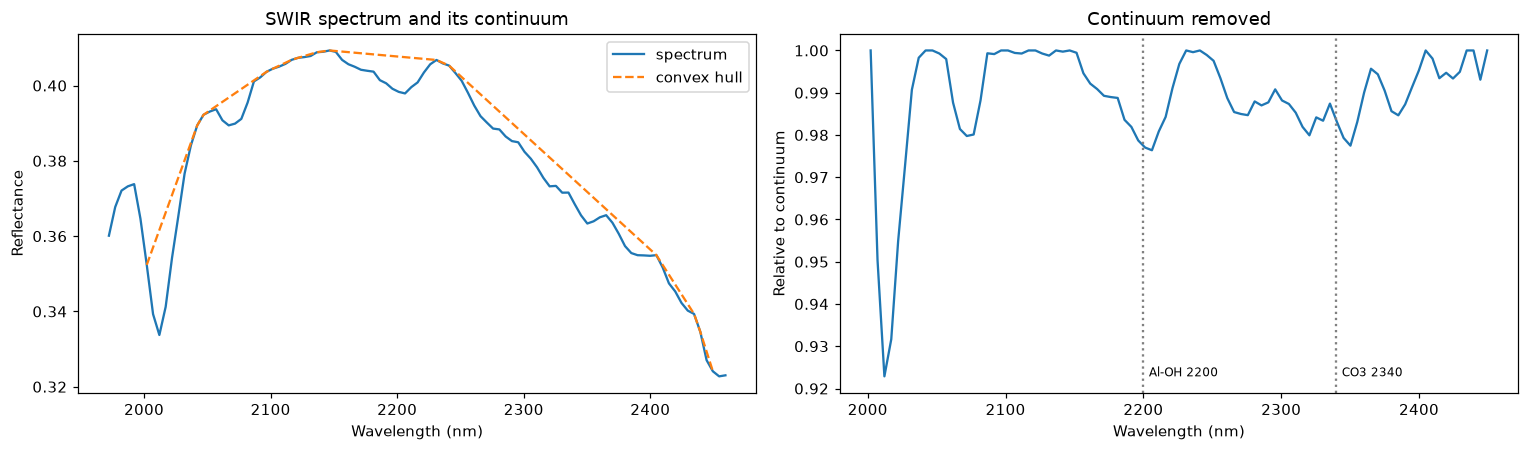

In [14]:
em = hs.read_tanager(tanager_file("energy-mining"), window=(slice(400, 650), slice(350, 600)), wavelength_range=(1950, 2460))
em = em.isel(band=np.flatnonzero(em["good"].values))  # good SWIR bands
em_s = hs.smooth(em, window=7)  # light smoothing helps feature depth on 5 nm bands
cr, hull = hs.continuum_removal(em_s, start=2000, stop=2450, return_hull=True)  # ratio to the convex hull
r0, c0 = 120, 120  # one pixel
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(hs.wavelengths(em_s), em_s.values[:, r0, c0], label="spectrum")
axes[0].plot(hs.wavelengths(hull), hull.values[:, r0, c0], "--", label="convex hull")
axes[0].set(title="SWIR spectrum and its continuum", xlabel="Wavelength (nm)", ylabel="Reflectance"); axes[0].legend()
axes[1].plot(hs.wavelengths(cr), cr.values[:, r0, c0])
for w, t in [(2200, "Al-OH 2200"), (2340, "CO3 2340")]:
    axes[1].axvline(w, color="0.5", ls=":"); axes[1].text(w + 4, float(cr.values[:, r0, c0].min()), t, fontsize=8)
axes[1].set(title="Continuum removed", xlabel="Wavelength (nm)", ylabel="Relative to continuum")
plt.tight_layout()
plt.show()

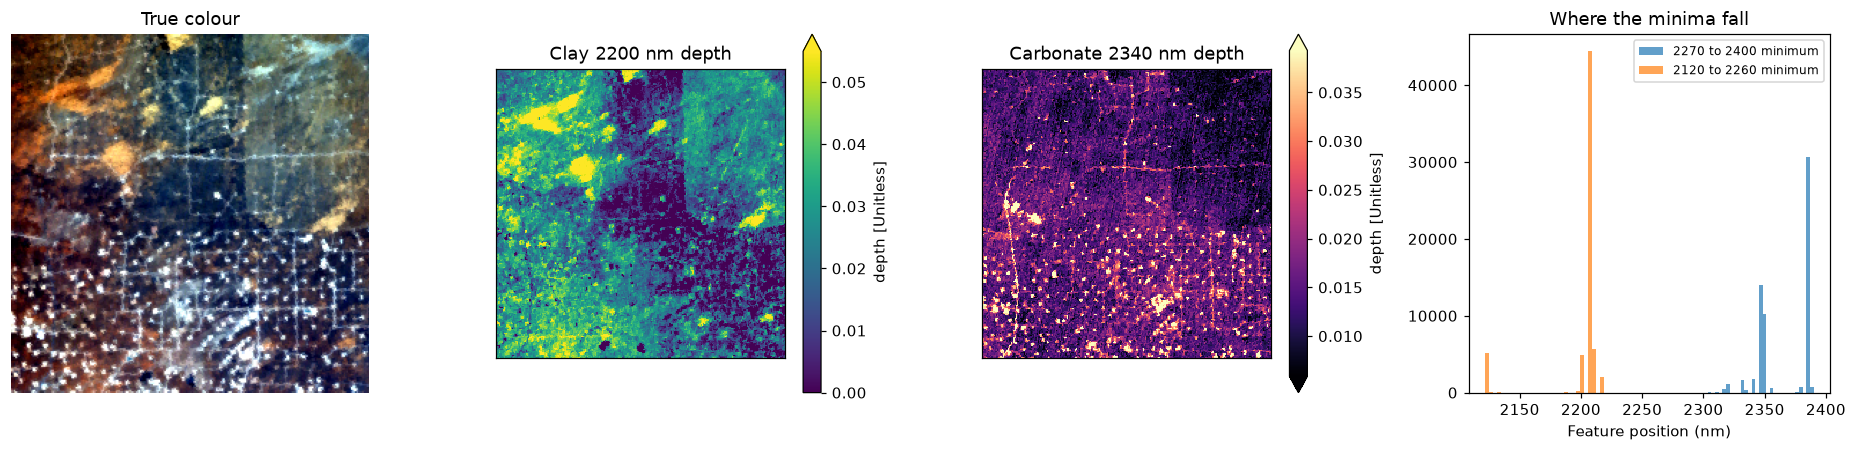

,clay depth,carbonate depth
count,62500.000,62500.000
mean,0.023,0.016
std,0.014,0.008
min,0.000,0.000
25%,0.012,0.011
50%,0.023,0.014
75%,0.032,0.018
max,0.075,0.157


In [15]:
clay = hs.band_depth(em_s, 2205, 2120, 2260)  # depth, position, width, area, asymmetry
carb = hs.band_depth(em_s, 2340, 2270, 2400)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
hs.plot_rgb(hs.read_tanager(tanager_file("energy-mining"), window=(slice(400, 650), slice(350, 600)),
                            bands=[37, 55, 17]), (651, 561, 461), ax=axes[0], title="True colour")
clay["depth"].plot(ax=axes[1], cmap="viridis", robust=True); axes[1].set_title("Clay 2200 nm depth")
carb["depth"].plot(ax=axes[2], cmap="magma", robust=True); axes[2].set_title("Carbonate 2340 nm depth")
axes[3].hist(carb["position"].values.ravel(), bins=40, alpha=0.7, label="2270 to 2400 minimum")
axes[3].hist(clay["position"].values.ravel(), bins=40, alpha=0.7, label="2120 to 2260 minimum")
axes[3].set(xlabel="Feature position (nm)", title="Where the minima fall"); axes[3].legend(fontsize=8)
for ax in axes[1:3]:
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()
pd.DataFrame({"clay depth": clay["depth"].values.ravel(), "carbonate depth": carb["depth"].values.ravel()}).describe().round(3)

The continuum removed spectrum shows the clay and carbonate features as shallow dips of 2 to 3
percent; the deepest dip, near 2010 nm, is residual CO₂ absorption from the atmosphere, not a
mineral. The depth maps follow the landscape: well pads and roads, built from crushed caliche
(calcium carbonate), stand out as a grid of dots and lines in the carbonate map, while the clay map
follows field and soil boundaries. The histograms of feature position are the quality check. Clay
minima cluster tightly at about 2205 nm. Carbonate minima split between about 2345 nm, the real
feature, and the right end of the window near 2390 nm, where noise and the falling continuum create
spurious minima; depths at those pixels mean little. Mineral mapping proper, with library
matching, follows in notebook 09_05_06.


## Simulating multispectral sensors

`hs.resample_to_sensor` convolves the cube with Gaussian approximations of a sensor's band
responses and returns a Dataset with canonical band names (`blue`, `red`, `nir`, `swir16`, ...),
the same names `geolattice.rsense.optical` uses.


['coastal', 'blue', 'green', 'red', 'rededge1', 'rededge2', 'rededge3', 'nir', 'nir08', 'watervapor', 'swir16', 'swir22']


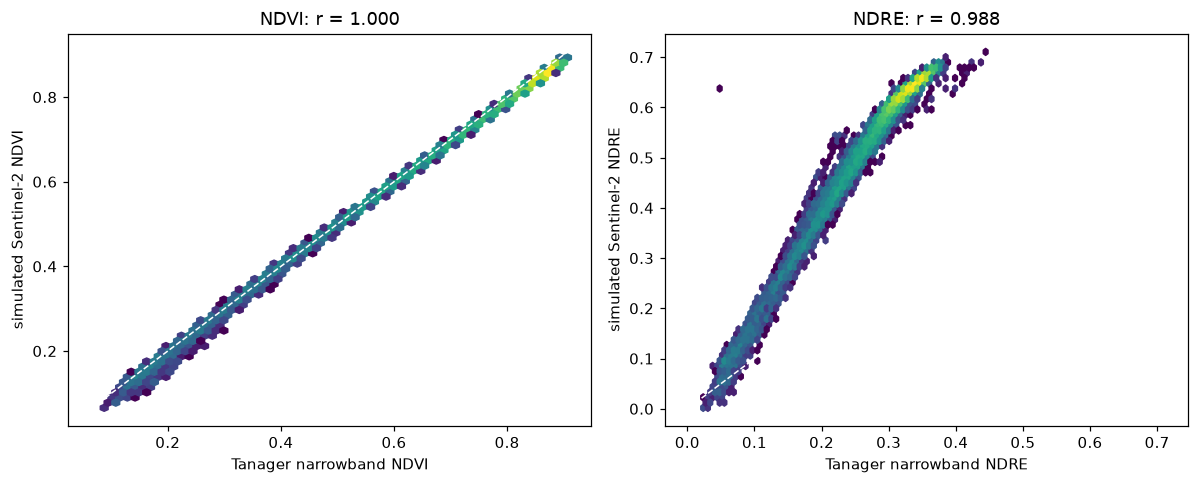

In [16]:
s2 = hs.resample_to_sensor(sr, "sentinel2")  # simulated Sentinel-2 bands
print(list(s2.data_vars))
ndvi_s2 = (s2["nir"] - s2["red"]) / (s2["nir"] + s2["red"])  # broadband NDVI (B8, B4)
ndvi_hs = hs.index(sr, "NDVI")  # narrowband NDVI from the nearest Tanager bands
ndre_s2 = (s2["nir08"] - s2["rededge1"]) / (s2["nir08"] + s2["rededge1"])  # Sentinel-2 red edge index
ndre_hs = hs.index(sr, "NDRE")  # narrowband NDRE

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (a, b, t) in zip(axes, [(ndvi_hs, ndvi_s2, "NDVI"), (ndre_hs, ndre_s2, "NDRE")]):
    x, y = a.values.ravel(), b.values.ravel()
    ok = np.isfinite(x) & np.isfinite(y)
    ax.hexbin(x[ok], y[ok], gridsize=60, bins="log", cmap="viridis")
    lim = [min(x[ok].min(), y[ok].min()), max(x[ok].max(), y[ok].max())]
    ax.plot(lim, lim, "w--", lw=1)
    ax.set(xlabel=f"Tanager narrowband {t}", ylabel=f"simulated Sentinel-2 {t}",
           title=f"{t}: r = {np.corrcoef(x[ok], y[ok])[0, 1]:.3f}")
plt.tight_layout()
plt.show()

Simulated Sentinel-2 NDVI is almost identical to the narrowband NDVI (r = 1.000, on the 1:1 line):
red and NIR reflectance are flat enough across the band widths that averaging changes little. NDRE
is different. Sentinel-2's red edge band 5 (704 nm, 15 nm wide) sits on the steep slope of the red
edge, and the simulated index runs well above the narrowband version, with more scatter (r = 0.988).
Indices built on steep parts of the spectrum change systematically with band width and position. Models trained on hyperspectral data should therefore be applied to
multispectral data only after resampling the training spectra, never with the narrowband formulas.


## Summary and exercises

**Key points**

- Remove the opaque water vapour bands and the noisy ends of the range; an SNR threshold catches
  more, at the cost of bands.
- Noise estimates differ by method: the residual method is closest to Tanager's own uncertainty;
  the shift difference method mistakes texture for noise.
- Pushbroom striping lives in sensor geometry. Column moment matching removes visible stripes but
  can raise absolute error; the Tanager and OHS L1 data here barely need it.
- Simple reflectance rules separate water, land and shadow, but neither they nor the beta product
  mask catch thin cloud over the ocean: inspect masks, do not trust them blindly.
- With uniform atmosphere an empirical line from two targets reproduces surface reflectance well;
  flat field and IAR give only relative spectra.
- Smoothing, derivatives, normalisation and continuum removal each bring out different parts of a
  spectrum; band depth maps turn absorption features into mineral or biochemical maps.
- Resampling to a multispectral sensor changes index values; resample before transferring models.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `read_tanager_ancillary`,
`read_ohs`, `bad_bands`, `drop_bad_bands`, `estimate_noise`, `destripe`, `quality_mask`,
`empirical_line`, `flat_field`, `iar_reflectance`, `smooth`, `derivative`, `red_edge_position`,
`snv`, `normalize`, `continuum_removal`, `band_depth`, `index`, `resample_to_sensor`, `plot_rgb`.

**Exercises**

1. Run `bad_bands(sr, min_snr=...)` for thresholds 2, 5 and 10 and count the remaining bands in the
   VNIR and SWIR.
2. Destripe the Tanager swath with `method="median"` and compare the stripe index with moment
   matching.
3. Use three empirical line targets (add a field of intermediate brightness). Does the RMSE change?
4. Map the 2200 nm clay depth with `feature=False` (depth at the fixed centre) and compare it with
   the feature based depth.
5. Simulate Landsat 8/9 with `resample_to_sensor(sr, "landsat89")` and compare its NDVI with the
   Sentinel-2 simulation.
